# PBMC3k: PCA Reference and Fixed CSP Results

This report summarizes the fixed CSP experiment and PCA reference results. Both methods use the same cells, highly variable genes, and `X_scaled`. CSP uses `H=50`, RSP, loading-column L2 norm weighting, and all 50 score columns, with Leiden `resolution=0.40`, yielding 9 clusters. Raw labels are 0–8, while display labels in figures and tables are 1–9. ARI/AMI measure clustering agreement only, not cell-type accuracy.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score
from IPython.display import Image, display

pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

ROOT = Path.cwd()
if not (ROOT / 'PBMC').is_dir():
    ROOT = ROOT.parent
DATA = ROOT / 'PBMC' / 'data'
FIGURES = ROOT / 'PBMC' / 'figures'
STEM = 'notebook_scaled_csp_norm_d50_r0p4_k9_n20000_b10000_t10_h50'
PCA_STEM = 'notebook_scaled_pca_baseline'
CSP_NAME = 'csp_scaled_norm_d50'
paths = {
    'csp_h5ad': DATA / f'{STEM}.h5ad',
    'csp_model': DATA / f'{STEM}_model.npz',
    'pca_markers': DATA / f'{PCA_STEM}_scaled_top5_markers.csv',
    'csp_markers': DATA / f'{STEM}_top5_markers.csv',
}
for path in paths.values():
    assert path.is_file(), path
adata = sc.read_h5ad(paths['csp_h5ad'])
meta = adata.uns[CSP_NAME]
diagnostics = meta['diagnostics']
with np.load(paths['csp_model'], allow_pickle=False) as model:
    saved_diagnostics = json.loads(model['diagnostics_json'].item())
assert saved_diagnostics['representation']['input_matrix'] == 'X_scaled'
assert saved_diagnostics['representation']['n_columns'] == 50
METHODS = {
    'PCA_scaled': {
        'cluster': 'leiden_scaled',
        'umap': 'umap_scaled',
        'markers': 'markers_scaled',
    },
    'CSP': {
        'cluster': meta['run']['leiden'],
        'umap': meta['run']['umap'],
        'markers': meta['run']['markers'],
    },
}
ORDER = ['PCA_scaled', 'CSP']
for name in ORDER:
    assert adata.obs[METHODS[name]['cluster']].notna().all()
print({'PCA_scaled': adata.shape, 'CSP': adata.shape, 'score': adata.obsm[f'X_{CSP_NAME}'].shape})

{'PCA_scaled': (2638, 13714), 'CSP': (2638, 13714), 'score': (2638, 50)}


## 1. Cluster Counts, ARI/AMI, and Cluster Sizes

ARI measures agreement in how cells are paired across clusters, while AMI measures shared information between two clusterings. Both are invariant to cluster-label permutation and are not classification accuracies.

In [2]:
def labels(method):
    raw = adata.obs[METHODS[method]['cluster']].astype(int)
    return pd.Series((raw + 1).astype(str), index=raw.index, dtype='category')

rows = []
for name in ORDER:
    rows.append({
        'Method': 'PCA' if name == 'PCA_scaled' else 'CSP',
        'Clusters': labels(name).nunique(),
        'ARI vs PCA': adjusted_rand_score(labels('PCA_scaled'), labels(name)),
        'AMI vs PCA': adjusted_mutual_info_score(labels('PCA_scaled'), labels(name)),
    })
metrics = pd.DataFrame(rows).set_index('Method')
display(metrics.round(4))
print(metrics.round(4).to_string())

cluster_sizes = pd.DataFrame({name: labels(name).value_counts().sort_index() for name in ORDER})
cluster_sizes = cluster_sizes.astype('Int64')
cluster_sizes.index.name = 'Cluster'
display(cluster_sizes)
print(cluster_sizes.to_string())

,Clusters,ARI vs PCA,AMI vs PCA
Method,,,
PCA,8,1.0000,1.000
CSP,9,0.6388,0.791


        Clusters  ARI vs PCA  AMI vs PCA
Method                                  
PCA            8      1.0000       1.000
CSP            9      0.6388       0.791


,PCA_scaled,CSP
Cluster,,
1,1158,567
2,300,295
3,343,570
4,479,348
5,156,450
6,159,177
7,30,156
8,13,28
9,<NA>,47


         PCA_scaled  CSP
Cluster                 
1              1158  567
2               300  295
3               343  570
4               479  348
5               156  450
6               159  177
7                30  156
8                13   28
9              <NA>   47


## 2. UMAP Comparison

UMAP is used for visualization only and is not, by itself, evidence that one method is better than another.

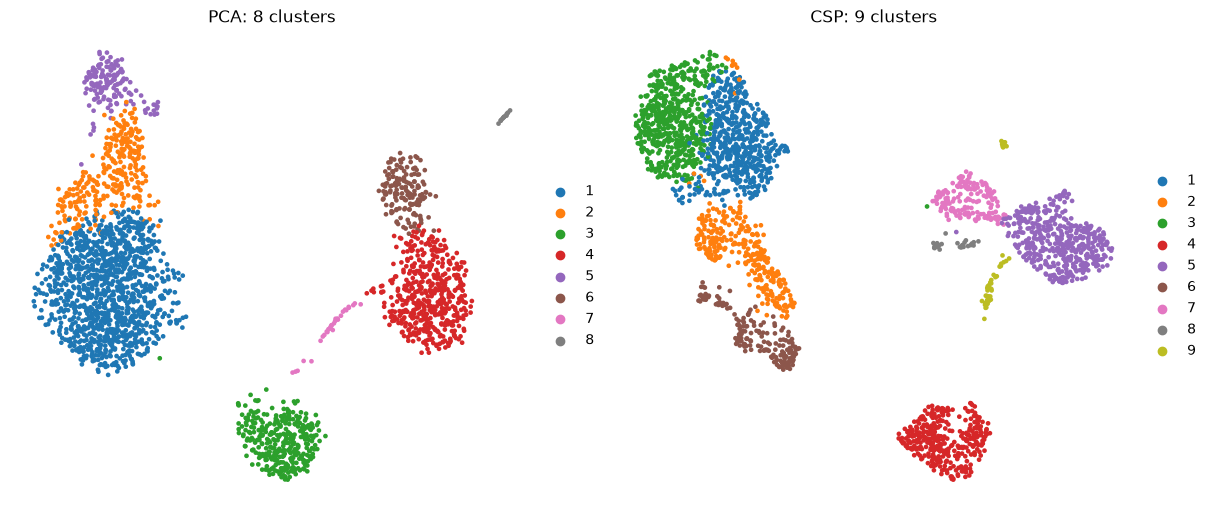

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, name in zip(axes.ravel(), ORDER):
    info = METHODS[name]
    plot_key = f'_report_label_{name}'
    adata.obs[plot_key] = labels(name)
    method_label = 'PCA' if name == 'PCA_scaled' else 'CSP'
    sc.pl.embedding(
        adata,
        basis=info['umap'],
        color=plot_key,
        title=f'{method_label}: {labels(name).nunique()} clusters',
        frameon=False,
        show=False,
        ax=ax,
    )
display(fig)
plt.close(fig)

## 3. Top-5 Markers per Cluster

This table reads the Wilcoxon rankings stored in the results, using log-normalized expression across all quality-control genes. Cluster labels are shown starting at 1.

In [4]:
marker_rows = []
for name in ORDER:
    result = adata.uns[METHODS[name]['markers']]
    for group in result['names'].dtype.names:
        marker_rows.append({
            'Method': 'PCA' if name == 'PCA_scaled' else 'CSP',
            'Cluster': int(group) + 1,
            'Top 5 markers': ', '.join(map(str, result['names'][group][:5])),
        })
marker_table = pd.DataFrame(marker_rows)
display(marker_table)
print(marker_table.to_string(index=False))

,Method,Cluster,Top 5 markers
0,PCA,1,"LDHB, RPS12, RPS25, RPS27, RPS6"
1,PCA,2,"CCL5, NKG7, B2M, GZMA, CST7"
2,PCA,3,"CD74, CD79A, HLA-DRA, CD79B, HLA-DPB1"
3,PCA,4,"LYZ, S100A9, S100A8, TYROBP, FTL"
4,PCA,5,"NKG7, GNLY, GZMB, CTSW, PRF1"
5,PCA,6,"LST1, FCER1G, AIF1, FCGR3A, COTL1"
6,PCA,7,"HLA-DPA1, HLA-DPB1, HLA-DRB1, HLA-DRA, CD74"
7,PCA,8,"PF4, SDPR, GNG11, PPBP, NRGN"
8,CSP,1,"LTB, IL32, LDHB, CD3D, IL7R"
9,CSP,2,"CCL5, NKG7, GZMA, B2M, CST7"


Method  Cluster                               Top 5 markers
   PCA        1             LDHB, RPS12, RPS25, RPS27, RPS6
   PCA        2                 CCL5, NKG7, B2M, GZMA, CST7
   PCA        3       CD74, CD79A, HLA-DRA, CD79B, HLA-DPB1
   PCA        4            LYZ, S100A9, S100A8, TYROBP, FTL
   PCA        5                NKG7, GNLY, GZMB, CTSW, PRF1
   PCA        6           LST1, FCER1G, AIF1, FCGR3A, COTL1
   PCA        7 HLA-DPA1, HLA-DPB1, HLA-DRB1, HLA-DRA, CD74
   PCA        8                PF4, SDPR, GNG11, PPBP, NRGN
   CSP        1                 LTB, IL32, LDHB, CD3D, IL7R
   CSP        2                 CCL5, NKG7, GZMA, B2M, CST7
   CSP        3            RPS27, RPS12, RPS6, RPL32, RPS14
   CSP        4       CD74, HLA-DRA, CD79A, CD79B, HLA-DPB1
   CSP        5            LYZ, S100A9, S100A8, TYROBP, FTL
   CSP        6                NKG7, CTSW, CST7, GNLY, GZMB
   CSP        7             LST1, FCER1G, AIF1, COTL1, FTH1
   CSP        8              OAZ1, ACTB,

## 4. Runtime Configuration and Sampling Diagnostics

CSP uses a single sampling chain. Low ESS or truncation saturation still requires caution: neither a long chain nor stable clustering proves that the full posterior has been adequately explored.

In [5]:
config = json.loads(meta['config_json'])
fit = diagnostics['fit']
sampling = diagnostics['sampling']
rsp = diagnostics['rsp']
h_star = sampling['h_star_summary']
diagnostic_rows = [
    ('Input', 'X_scaled'),
    ('H', config['H']),
    ('alpha', config['alpha']),
    ('theta_inf', config['theta_inf']),
    ('RSP status', rsp['status_code']),
    ('Score weighting', diagnostics['score_weighting']),
    ('Score columns', adata.obsm[f'X_{CSP_NAME}'].shape[1]),
    ('Leiden resolution', config['leiden_resolution']),
    ('Report clusters', labels('CSP').nunique()),
    ('Fit sweeps', fit['n_iter']),
    ('Burn-in', fit['burn_in']),
    ('Thin', fit['thin']),
    ('Kept draws', fit['n_kept']),
    ('Runtime seconds', round(fit['runtime_sec'], 2)),
    ('Backend', fit['backend']),
    ('H* mean', h_star['mean']),
    ('H* 95% CI', str(h_star['ci'])),
    ('HPD active factors', diagnostics['hpd_active_factor_count']),
    ('Minimum bulk ESS (loadings)', round(sampling['bulk_summary']['B']['min'], 2)),
    ('Minimum bulk ESS (noise variances)', round(sampling['bulk_summary']['sigma2']['min'], 2)),
    ('Review required', diagnostics['validation_status']),
]
diagnostic_table = pd.DataFrame(diagnostic_rows, columns=['Item', 'CSP'])
display(diagnostic_table)
print(diagnostic_table.to_string(index=False))

ess_rows = []
for method in ('bulk_summary', 'tail_summary'):
    for variable, values in sampling[method].items():
        ess_rows.append({'summary': method, 'variable': variable, **values})
display(pd.DataFrame(ess_rows))
display(pd.DataFrame([sampling['score_half_stability']]))
print(sampling['chain_coordinate_note'])
print(sampling['truncation_note'])

,Item,CSP
0,Input,X_scaled
1,H,50
2,alpha,5.0
3,theta_inf,0.05
4,RSP status,1
5,Score weighting,loading_column_l2_norm
6,Score columns,50
7,Leiden resolution,0.4
8,Report clusters,9
9,Fit sweeps,20000


                              Item                    CSP
                             Input               X_scaled
                                 H                     50
                             alpha                    5.0
                         theta_inf                   0.05
                        RSP status                      1
                   Score weighting loading_column_l2_norm
                     Score columns                     50
                 Leiden resolution                    0.4
                   Report clusters                      9
                        Fit sweeps                  20000
                           Burn-in                  10000
                              Thin                     10
                        Kept draws                   1000
                   Runtime seconds                2898.68
                           Backend                    cpu
                           H* mean                   49.0
              

,summary,variable,max,mean,median,min,n_draws
0,bulk_summary,B,1163.513321,83.619705,38.119483,1.326110,1000
1,bulk_summary,H_star,1000.000000,1000.000000,1000.000000,1000.000000,1000
2,bulk_summary,sigma2,1229.304348,938.346405,953.378479,273.879661,1000
3,tail_summary,B,1120.930638,229.334480,159.112140,10.639948,1000
4,tail_summary,H_star,1000.000000,1000.000000,1000.000000,1000.000000,1000
5,tail_summary,sigma2,1122.717609,911.951691,918.868627,448.967888,1000


,absolute_difference_max,absolute_difference_median,relative_difference_max,relative_difference_median,split_draw
0,1.845807,0.014302,9921.872571,0.064359,500


H* and same-index B differ by half a sweep; use marginal summaries, not per-draw joint interpretation. H* is not defined after RSP.
Every retained draw has H*=H-1; the dimension posterior and truncation are not validated.


## 5. Loading-Column Norms Before and After RSP

Compare the L2 norms of loading columns from the posterior mean loadings before and after RSP alignment.

PBMC\figures\notebook_scaled_csp_norm_d50_r0p4_k9_n20000_b10000_t10_h50\loading_column_norms_csp_scaled_norm_d50.png


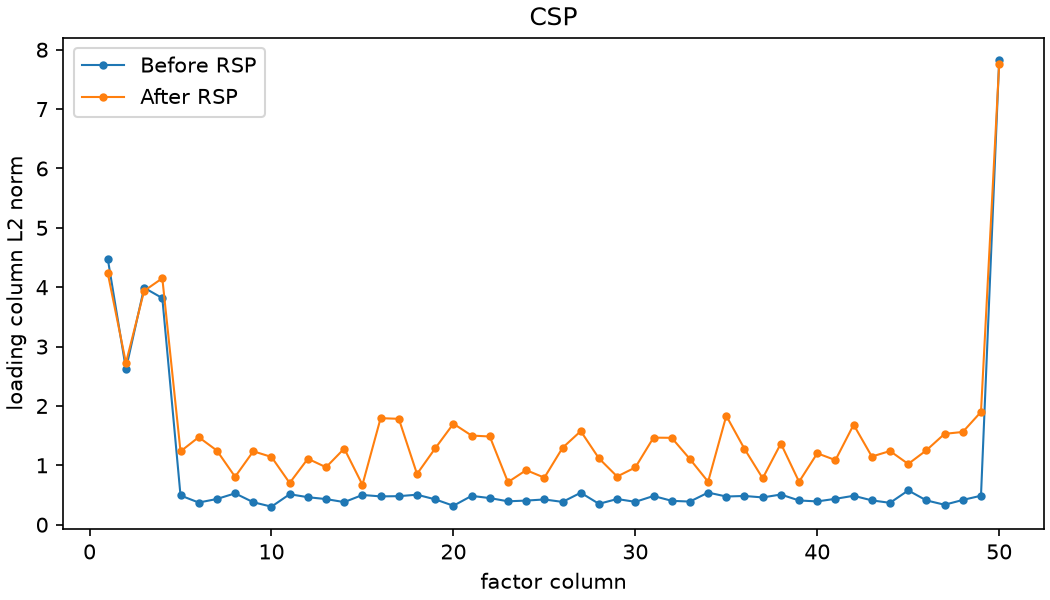

In [6]:
figure_paths = [
    FIGURES / STEM / f'loading_column_norms_{CSP_NAME}.png',
]
for path in figure_paths:
    assert path.is_file(), path
    print(path.relative_to(ROOT))
    display(Image(filename=str(path)))